<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%ED%8F%89%EA%B7%A0%EC%A0%9C%EA%B3%B1%EC%98%A4%EC%B0%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 손실 함수가 필요한 이유
- 신경망의 내부 가중치 파라미터를 조절하여 함수를 근사계산할 수 있음
- 얼마나 잘 근사계산하는지 알아야 더 좋은 가중치 파라미터를 선택할 수 있음
- 손실 값은 얼마나 잘 근사계산하는지 수치로 나타낸 것(낮을수록 좋음)
- 선형 계층의 가중치 파라미터 변화에 따라 손실 값이 변할 것
- 가중치 파라미터를 입력을 받아 손실 값을 출력으로 변환하는 함수를 만들 수 있는데 이것이 손실 함수임

### 손실함수
- 입력:가중치 파라미터
- 출력:손실값

In [3]:
import torch
import torch.nn as nn
class MyLinear(nn.Module):
  def __init__(self,input_dim=3,output_dim=2):
    self.input_dim=input_dim
    self.output_dim=output_dim

    super().__init__()

    self.linear=nn.Linear(input_dim,output_dim)

  def forward(self,x):
    y=self.linear(x)
    return y


In [4]:
device="cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


### MSE Loss

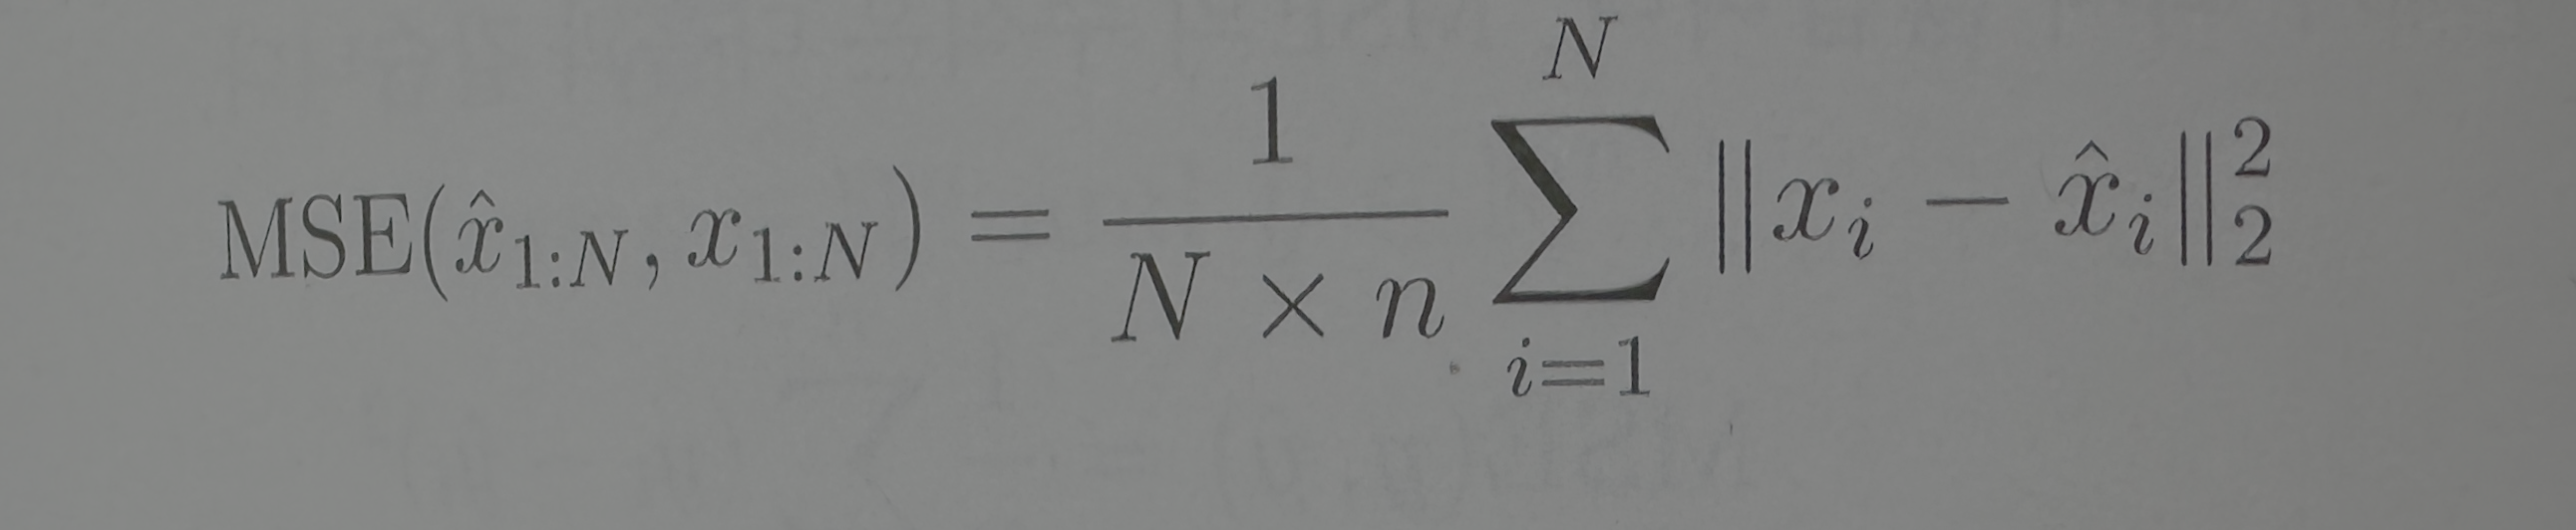

이 수식을 코드로 옮기면 다음과 같습니다.

In [6]:
def mse(x_hat,x):
  #|x_hat|=(batch_size,dim)
  #|x|=(batch_size,dim)
  y=((x-x_hat)**2).mean()

  return y

In [7]:
x=torch.FloatTensor([[1,1],
                     [2,2]])
x_hat=torch.FloatTensor([[0,0],
                         [0,0]])
print(mse(x_hat,x))

tensor(2.5000)


### torch.nn.functional


In [8]:
import torch.nn.functional as F
F.mse_loss(x_hat,x)

tensor(2.5000)

### torch.nn 사용하기

이 방법을 사용하게 되면 `nn.Module`의 하위 클래스 내부에 선언하기 때문에 계층의 하나처럼 취급할 수 있습니다.

In [9]:
import torch.nn as nn
mse_loss=nn.MSELoss()
mse_loss(x_hat,x)

tensor(2.5000)